# ЛР2. Поріг рішення під асиметричну ціну помилок

## Короткий опис

Модель навчається один раз на фіксованому train/validation/test split. На validation поріг `t* = 0,037034064531326294` зменшує вартість `C = 10·FN + FP` з 269 при стандартному порозі 0,5 до 188. На test отримано `TP=80`, `FP=35`, `FN=19`, `TN=56 828`, `C=225`, precision `0,695652` і recall `0,808081`.

Цей ноутбук є дослідницьким поясненням до [lab2.py](lab2.py). Клітини виконуються зверху вниз: спочатку перевіряються дані й split, потім навчається модель, після цього окремо досліджується поріг і лише наприкінці оцінюється test.


## Контекст і метод

Використовується набір Credit Card Fraud Detection (ULB/Kaggle). Вхідні ознаки — `V1`–`V28` і сирий `Amount`; `Time` та `Class` до моделі не входять. Модель має вигляд `Linear(29, 32) → ReLU → Linear(32, 1)` і навчається з `BCEWithLogitsLoss`, Adam (`lr=10⁻³`), 12 епохами та пакетами по 1024.

Рішення вважаємо шахрайством, коли `sᵢ = sigmoid(zᵢ) ≥ t`. Асиметрична вартість помилок:

`C(t) = 10·FN(t) + FP(t)`.

Ключове припущення: threshold підбирається тільки на validation. Test використовується один раз після завершення перевірок пошуку.


In [1]:
from pathlib import Path
import os
import sys

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display

# Працюємо і з кореня репозиторію, і з теки Lab2.
working_dir = Path.cwd()
lab_dir = working_dir / "Lab2" if (working_dir / "Lab2" / "lab2.py").exists() else working_dir
sys.path.insert(0, str(lab_dir))

from lab2 import (  # noqa: E402
    analyze_saved,
    best_threshold,
    candidate_table,
    evaluate_threshold,
    load_saved_predictions,
    make_splits,
    save_training_outputs,
    split_summary,
    train_model,
    verify_cases,
)

csv_candidates = [
    Path(os.environ["CREDITCARD_CSV"]) if os.environ.get("CREDITCARD_CSV") else None,
    working_dir / "creditcard.csv",
    working_dir.parent / "creditcard.csv",
]
csv_path = next((path for path in csv_candidates if path and path.exists()), None)
if csv_path is None:
    raise FileNotFoundError("Задайте CREDITCARD_CSV або покладіть creditcard.csv поруч із DL/")

out_dir = lab_dir / "artifacts"
print(f"CSV: {csv_path.name}")
print(f"Артефакти: {out_dir.name}/")

CSV: creditcard.csv
Артефакти: artifacts/


### 1. Завантаження та фіксований поділ

In [2]:
frame = pd.read_csv(csv_path)
print(f"Розмір таблиці: {frame.shape[0]:,} рядків × {frame.shape[1]} стовпців")
print(f"Шахрайських транзакцій: {int(frame['Class'].sum()):,} ({frame['Class'].mean():.4%})")

train_split, validation_split, test_split, scaler = make_splits(csv_path)
split_data = {
    "train_labels": train_split.y,
    "validation_labels": validation_split.y,
    "test_labels": test_split.y,
}
split_overview = split_summary(split_data)
display(split_overview.style.format({"positive_fraction": "{:.4%}"}))

Розмір таблиці: 284,807 рядків × 31 стовпців
Шахрайських транзакцій: 492 (0.1727%)


,split,n,positives,positive_fraction
0,train,170884,295,0.1726%
1,validation,56961,98,0.1720%
2,test,56962,99,0.1738%


`StandardScaler` навчається тільки на train. Це важливо: якщо використати validation або test для середнього й масштабу, підготовка моделі отримає інформацію з відкладених даних.

In [3]:
print("Перші три середні scaler:", np.round(scaler.mean_[:3], 6))
print("Перші три масштаби scaler:", np.round(scaler.scale_[:3], 6))
print("Тип входів моделі:", train_split.x.dtype)

Перші три середні scaler: [ 0.002938 -0.000256  0.001434]
Перші три масштаби scaler: [1.954597 1.65249  1.510407]
Тип входів моделі: float32


### 2. Одне навчання моделі

In [4]:
# Це єдина клітина навчання; фіксовані зерна роблять повторний запуск детермінованим.
model, loss_history = train_model(train_split)
loss_table = pd.DataFrame({"epoch": np.arange(1, len(loss_history) + 1), "BCE": loss_history})
display(loss_table.style.format({"BCE": "{:.8f}"}))

epoch  1/12 loss=0.36603008


epoch  2/12 loss=0.05497654


epoch  3/12 loss=0.01689432


epoch  4/12 loss=0.00947625


epoch  5/12 loss=0.00681831


...

epoch  9/12 loss=0.00395529


epoch 10/12 loss=0.00372137


epoch 11/12 loss=0.00351828


epoch 12/12 loss=0.00336972


,epoch,BCE
0,1,0.36603008
1,2,0.05497654
2,3,0.01689432
3,4,0.00947625
4,5,0.00681831
5,6,0.00551745
6,7,0.00475719
7,8,0.00428474
8,9,0.00395529
9,10,0.00372137


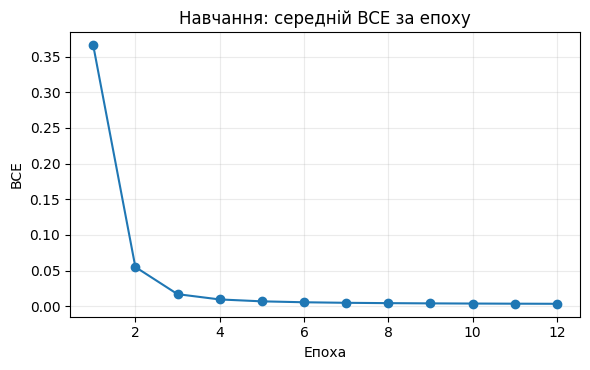

In [5]:
fig, ax = plt.subplots(figsize=(6, 3.8))
ax.plot(loss_table["epoch"], loss_table["BCE"], marker="o", linewidth=1.5)
ax.set(title="Навчання: середній BCE за епоху", xlabel="Епоха", ylabel="BCE")
ax.grid(alpha=0.25)
fig.tight_layout()
plt.show()

In [6]:
# Зберігаємо оцінки без округлення; далі читаємо саме цей архів.
save_training_outputs(
    out_dir,
    model,
    (train_split, validation_split, test_split),
    scaler,
    csv_path,
    loss_history,
)
saved = load_saved_predictions(out_dir)
print("Збережені масиви:", ", ".join(sorted(saved)))

Збережені масиви: scaler_mean, scaler_scale, test_amount, test_indices, test_labels, test_scores, train_amount, train_indices, train_labels, validation_amount, validation_indices, validation_labels, validation_scores


### 3. Validation: PR/ROC і якість ранжування

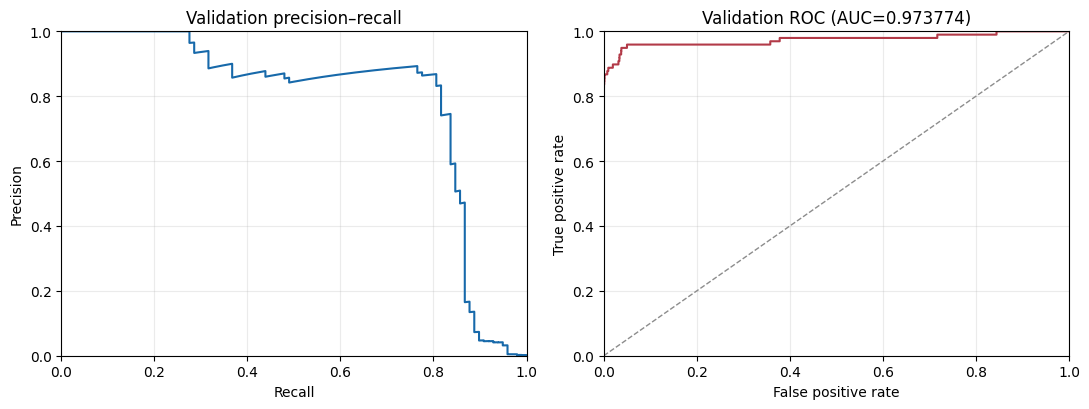

ROC-AUC = 0.973773879


In [7]:
validation_y = saved["validation_labels"]
validation_scores = saved["validation_scores"]

from sklearn.metrics import auc, precision_recall_curve, roc_curve

precision, recall, _ = precision_recall_curve(validation_y, validation_scores)
false_positive_rate, true_positive_rate, _ = roc_curve(validation_y, validation_scores)
roc_auc = auc(false_positive_rate, true_positive_rate)

fig, axes = plt.subplots(1, 2, figsize=(11, 4.2))
axes[0].plot(recall, precision, color="#1769aa")
axes[0].set(title="Validation precision–recall", xlabel="Recall", ylabel="Precision", xlim=(0, 1), ylim=(0, 1))
axes[1].plot(false_positive_rate, true_positive_rate, color="#b23a48")
axes[1].plot([0, 1], [0, 1], linestyle="--", color="0.55", linewidth=1)
axes[1].set(title=f"Validation ROC (AUC={roc_auc:.6f})", xlabel="False positive rate", ylabel="True positive rate", xlim=(0, 1), ylim=(0, 1))
for axis in axes:
    axis.grid(alpha=0.25)
fig.tight_layout()
plt.show()
print(f"ROC-AUC = {roc_auc:.9f}")

ROC-AUC оцінює ранжування за всіма порогами. Він не враховує, що пропущене шахрайство коштує у 10 разів дорожче за хибну тривогу, і не гарантує високої precision за дуже рідкісного позитивного класу.

### 4. Пошук порога через рівні оцінок і кумулятивні суми

In [8]:
validation_candidates = candidate_table(validation_y, validation_scores)
selected_threshold = best_threshold(validation_candidates)
best_rows = validation_candidates[validation_candidates["C"] == validation_candidates["C"].min()]
print(f"Обраний поріг: {selected_threshold:.17g}")
print(f"Мінімальна validation-вартість: {int(validation_candidates['C'].min())}")

# Показуємо початок, усі нічиї мінімуми та кінець без величезної таблиці.
preview = pd.concat([validation_candidates.head(3), best_rows, validation_candidates.tail(3)]).drop_duplicates()
display(preview)

Обраний поріг: 0.037034064531326294
Мінімальна validation-вартість: 188


,threshold,TP,FP,FN,TN,C
0,inf,0,0,98,56863,980
1,9.995752e-01,2,0,96,56863,960
2,9.992633e-01,3,0,95,56863,950
109,3.703406e-02,82,28,16,56835,188
55966,1.835119e-22,98,56861,0,2,56861
55967,1.090468e-27,98,56862,0,1,56862
55968,7.774516e-35,98,56863,0,0,56863


In [9]:
validation_comparison = pd.DataFrame(
    [
        {"rule": "Стандартний поріг", **evaluate_threshold(validation_y, validation_scores, 0.5)},
        {"rule": "Мінімум вартості", **evaluate_threshold(validation_y, validation_scores, selected_threshold)},
        {"rule": "Усі негативні", **evaluate_threshold(validation_y, validation_scores, float("inf"))},
    ]
)
display(validation_comparison)

,rule,threshold,TP,FP,FN,TN,C,precision,recall
0,Стандартний поріг,0.5,72,9,26,56854,269,0.888889,0.734694
1,Мінімум вартості,0.037034,82,28,16,56835,188,0.745455,0.836735
2,Усі негативні,+inf,0,0,98,56863,980,NaN,0.000000


Пороги із однаковою оцінкою отримують однаковий прогноз. Для `+∞` усі об'єкти негативні; найменша оцінка означає, що всі об'єкти позитивні. Якщо мінімум вартості повторюється, беремо найбільший поріг.

### 5. Незалежна перевірка пошуку

In [10]:
verification = verify_cases()
for name, (table, chosen) in verification.items():
    print(f"Набір {name}: обраний поріг = {chosen}")
    display(table)

Набір A: обраний поріг = 0.4


,threshold,TP,FP,FN,TN,C
0,inf,0,0,2,4,20
1,0.9,0,1,2,3,21
2,0.7,1,2,1,2,12
3,0.4,2,2,0,2,2
4,0.2,2,3,0,1,3
5,0.1,2,4,0,0,4


Набір B: обраний поріг = inf


,threshold,TP,FP,FN,TN,C
0,inf,0,0,0,3,0
1,0.9,0,1,0,2,1
2,0.6,0,2,0,1,2
3,0.3,0,3,0,0,3


Набір C: обраний поріг = 0.8


,threshold,TP,FP,FN,TN,C
0,inf,0,0,2,11,20
1,0.8,1,0,1,11,10
2,0.5,2,10,0,1,10
3,0.2,2,11,0,0,11


### 6. Test і перші помилки

In [11]:
# До test переходимо лише після вибору порога й усіх перевірок.
summary = analyze_saved(out_dir)
test_result = pd.DataFrame([summary["test"]])
display(test_result)
errors = pd.read_csv(out_dir / "test_errors.csv")
display(errors)

,threshold,TP,FP,FN,TN,C,precision,recall
0,0.037034,80,35,19,56828,225,0.695652,0.808081


,csv_row,error,label,score,Amount,score_minus_threshold
0,460,FP,0,0.186726,2.00,0.149692
1,2961,FP,0,0.069137,2.49,0.032103
2,10783,FP,0,0.964668,89.99,0.927634
3,13405,FP,0,0.928222,89.99,0.891188
4,13617,FP,0,0.918403,89.99,0.881369
5,10497,FN,1,0.010822,3.79,-0.026212
6,52521,FN,1,0.006813,105.99,-0.030222
7,55401,FN,1,0.005848,1.00,-0.031186
8,91671,FN,1,0.000526,290.18,-0.036508
9,93486,FN,1,0.018775,0.00,-0.018259


## Висновки

Поріг зменшив кількість `FN` на validation з 26 до 16, додавши 19 `FP`; вартість знизилася з 269 до 188. На test отримано зменшення `FN` з 28 до 19 ціною 27 додаткових `FP`, а вартість знизилася з 288 до 225. Це результат для цієї validation-вибірки, тому на нових даних такий самий виграш не гарантований.

Десять розібраних помилок не пояснюють причину роботи моделі: це мала вибірка, а рішення використовує всі 29 ознак. Сирий `Amount` допомагає описати приклади, але сам по собі не є формулою вартості помилок.


In [12]:
print("Файли, створені аналізом:")
for path in sorted(out_dir.iterdir()):
    if path.is_file():
        print(f"  {path.name:32s} {path.stat().st_size:>10,d} bytes")

Файли, створені аналізом:
  chosen_threshold.txt                     22 bytes
  model.pt                              6,217 bytes
  run.json                              1,048 bytes
  split_and_predictions.npz         7,294,910 bytes
  summary.json                          3,364 bytes
  test_errors.csv                         717 bytes
  validation_candidates.csv         2,583,237 bytes
  validation_pr.png                    29,624 bytes
  validation_roc.png                   27,348 bytes
  verification_A.csv                      198 bytes
  verification_B.csv                      133 bytes
  verification_C.csv                      125 bytes
